# Driven Damped Harmonic Oscillator: plain ANN vs Physics-Informed Neural Network (PINN)

**Goal.** Fit a noisy signal from a damped oscillator driven by a periodic external force and forecast beyond the observed time window, comparing:

| | Plain ANN | PINN |
|---|---|---|
| Information used | Noisy data only | Noisy data **+** the governing ODE (including the force) **+** initial conditions |
| Loss | $\mathcal{L} = \mathcal{L}_{data}$ | $\mathcal{L} = \mathcal{L}_{data} + \lambda_{phys}\,\mathcal{L}_{phys} + \lambda_{IC}\,\mathcal{L}_{IC}$ |

The physical system is (unit mass, under-damped $0 \le \zeta < 1$)

$$\ddot{x}(t) + 2\zeta\omega\,\dot{x}(t) + \omega^2 x(t) = F_0\cos(\Omega t)$$

Its exact solution is a decaying **transient** at the damped frequency $\omega_d = \omega\sqrt{1-\zeta^2}$ plus a **steady state** at the driving frequency $\Omega$:

$$x(t) = \underbrace{e^{-\zeta\omega t}\left[C_1\cos(\omega_d t) + C_2\sin(\omega_d t)\right]}_{\text{transient}}
+ \underbrace{G\cos(\Omega t - \delta)}_{\text{steady state}}, \qquad
G = \frac{F_0}{\sqrt{(\omega^2-\Omega^2)^2 + (2\zeta\omega\Omega)^2}}, \quad
\tan\delta = \frac{2\zeta\omega\Omega}{\omega^2-\Omega^2}$$

with $C_1, C_2$ fixed by the initial conditions. The parameters ($\omega = 3$, $\Omega = 10$ rad/s, $x(0) = 0.4$ rad) give a signal like a driven pendulum in the small-angle limit: the transient dies out and the motion locks onto the driving frequency, so the spectrum has **two peaks**.

**Why it is harder than the SHO.** Two time scales, a fast component ($\Omega$) of small amplitude, and a signal whose character changes over time (transient → steady state). Compared to the SHO notebook the network is wider and trained with a larger learning rate, otherwise neither model can even fit the fast component on the training window (spectral bias of tanh MLPs). Noise and $\lambda$'s are rescaled to the much smaller amplitudes.

**Fair comparison.** Both models share the *same* training data, test set, normalization, architecture (`SHONet`) and initial weights (same random seed). The only thing that changes is the **loss function**.

All the code lives in the `sho` package next to this notebook. The ODE and its exact solution are in `sho/physics.py` (`Oscillator`); an experiment is fully described by an `SHOConfig`.

**Notebook outline**
1. Setup
2. Experimental setup, the signal & time sampling schemes
3. Single experiment: ANN vs PINN in detail (3.4: physics over the forecast window)
4. Sampling-scheme sweep: how does *where* we observe affect each model?

## 1. Setup

In [1]:
#%load_ext autoreload
#%autoreload 2

from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt

from sho import *  # SHOConfig, run_experiment, compare_sampling_schemes, plot_* ...

## 2. Experimental setup (shared by both models)

- **Training data:** noisy observations over `n_periods_train` periods $T = 2\pi/\omega$, at times drawn from `sampling_train`.
- **Test data:** *new* noisy observations on times **after** the training window (forecasting), with independent noise (different seed).

Every field of `SHOConfig` has a default; override only what you want to change. Derive variants with `replace(cfg, ...)` or `cfg.with_sampling(name, **kwargs)`.

In [2]:
base_cfg = SHOConfig(
    # ---- Oscillator: x'' + 2 zeta omega x' + omega^2 x = F0 cos(Omega t) ----
    A=0.4, omega=3.0, phi=0.0,   # x(0) = 0.4 rad, x'(0) = 0
    zeta=0.1,                    # damping ratio
    F0=10.0, Omega=10.0,         # driving force amplitude (per unit mass) and frequency
    noise_std=0.03,              # std dev of Gaussian noise
    # ---- Training window (observed data), in natural periods T = 2 pi / omega ----
    n_periods_train=3.0, n_points=400,
    sampling_train="uniform", sampling_train_kwargs={},
    # ---- Test window (forecasting beyond the training data) ----
    period_factor=1.0, n_test_points=100, sampling_test="uniform",
    # ---- Shared model settings (identical for ANN and PINN) ----
    hidden_sizes=(64, 64, 64), model_seed=0,
    # ---- Training ----
    ann_lr=1e-3, ann_epochs=10_000,
    pinn_lr=1e-3, pinn_epochs=20_000, lambda_physics=1.0, lambda_ic=1.0,
    n_colloc=2000, colloc_t_end=None,   # None -> collocation only on the training window
    colloc_test_window=False,           # True -> collocation also over the test window
)
osc = base_cfg.oscillator
G, delta = osc.steady_state()
print(osc.name, "| omega_d =", round(osc.omega_d, 4), "rad/s | steady-state amplitude G =",
      round(G, 4), "| decay time 1/(zeta omega) =", round(1 / (osc.zeta * osc.omega), 3), "s")
base_cfg

Driven Damped Harmonic Oscillator | omega_d = 2.985 rad/s | steady-state amplitude G = 0.1097 | decay time 1/(zeta omega) = 3.333 s


SHOConfig(A=0.4, omega=3.0, phi=0.0, noise_std=0.03, zeta=0.1, F0=10.0, Omega=10.0, x0=None, v0=None, n_periods_train=3.0, n_points=400, sampling_train='uniform', sampling_train_kwargs={}, seed_train=42, period_factor=1.0, n_test_points=100, sampling_test='uniform', sampling_test_kwargs={}, seed_test=123, hidden_sizes=(64, 64, 64), model_seed=0, normalize=True, ann_lr=0.001, ann_epochs=10000, pinn_lr=0.001, pinn_epochs=20000, lambda_physics=1.0, lambda_ic=1.0, n_colloc=2000, colloc_t_end=None, colloc_test_window=False)

#### The signal
Ground truth over a long time span (no noise): displacement, phase portrait and power spectrum. The shaded region is the training window of `base_cfg`.

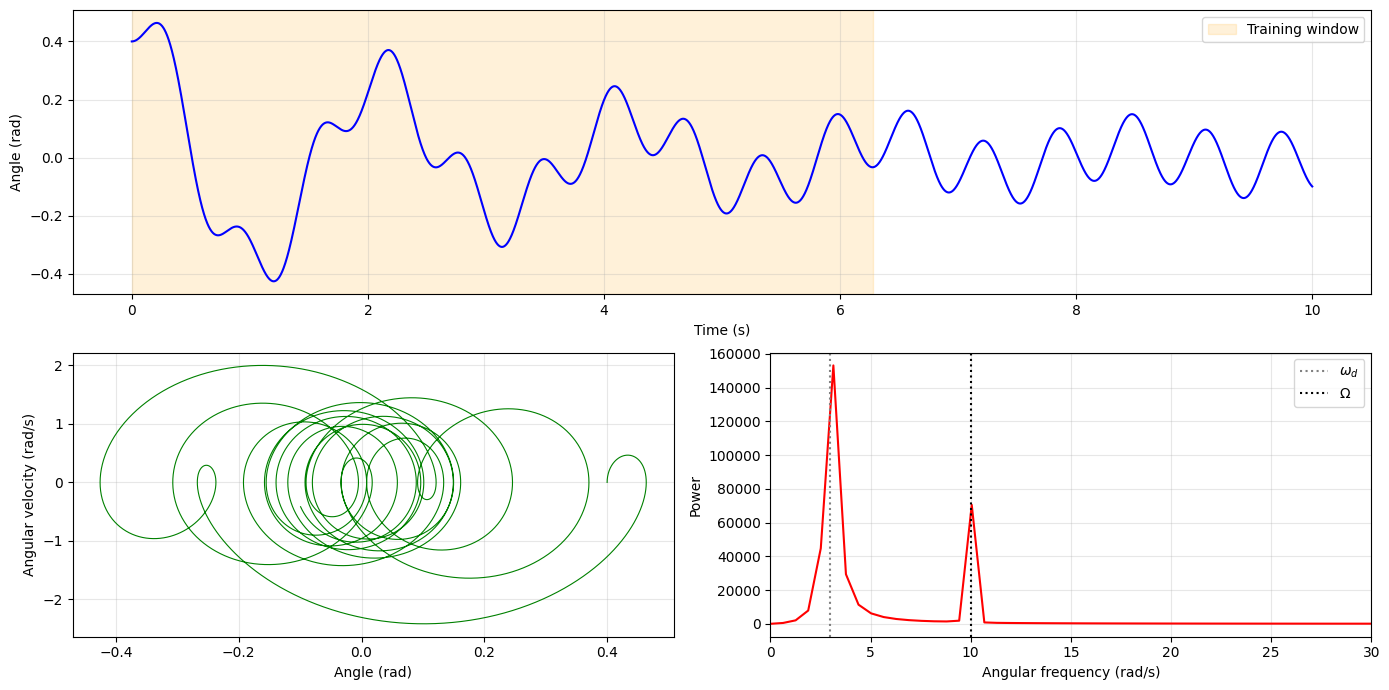

In [3]:
t_long = np.linspace(0, 10, 5000)
x0, v0 = base_cfg.initial_conditions
x_long, v_long = osc.solution(t_long, x0, v0), osc.velocity(t_long, x0, v0)

fig = plt.figure(figsize=(14, 7))
ax_x = fig.add_subplot(2, 1, 1)
ax_x.plot(t_long, x_long, color="blue")
ax_x.axvspan(0, base_cfg.n_periods_train * base_cfg.T, color="orange", alpha=0.15, label="Training window")
ax_x.set_xlabel("Time (s)"); ax_x.set_ylabel("Angle (rad)"); ax_x.legend(); ax_x.grid(alpha=0.3)

ax_p = fig.add_subplot(2, 2, 3)
ax_p.plot(x_long, v_long, color="green", linewidth=0.8)
ax_p.set_xlabel("Angle (rad)"); ax_p.set_ylabel("Angular velocity (rad/s)"); ax_p.grid(alpha=0.3)

ax_s = fig.add_subplot(2, 2, 4)
w = 2 * np.pi * np.fft.rfftfreq(t_long.size, t_long[1] - t_long[0])
ax_s.plot(w, np.abs(np.fft.rfft(x_long - x_long.mean()))**2, color="red")
ax_s.axvline(osc.omega_d, color="gray", linestyle=":", label="$\\omega_d$")
ax_s.axvline(osc.Omega, color="black", linestyle=":", label="$\\Omega$")
ax_s.set_xlim(0, 30); ax_s.set_xlabel("Angular frequency (rad/s)"); ax_s.set_ylabel("Power")
ax_s.legend(); ax_s.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Time sampling schemes

`sample_time_points` supports the schemes below (see its docstring for the parameters). Define here the ones you want to experiment with, as `name -> (sampling, sampling_kwargs)`. The name is only a label, so the same scheme can appear several times with different parameters.

In [4]:
print(sample_time_points.__doc__)
print("Default kwargs:", SAMPLING_SCHEMES)


    Return `n_points` sorted times in [t_start, t_end] following a sampling scheme.

    sampling options (optional keyword arguments and defaults in brackets):
      "uniform"      Evenly spaced grid (np.linspace).
      "random"       i.i.d. Uniform(t_start, t_end). Equivalent to the arrival times of a
                     homogeneous Poisson process conditioned on n_points events.
      "chebyshev"    Chebyshev-Lobatto nodes: dense at both ends, sparse in the middle.
      "beta"         Beta(a, b) rescaled to the interval [a=0.5, b=0.5].
                     a=b<1 -> both ends, a=b>1 -> centre, a<b -> start, a>b -> end.
      "normal"       Truncated Gaussian [mu=midpoint, sigma=span/6].
      "exponential"  Truncated exponential, dense at start [scale=span/3, reverse=False].
                     reverse=True makes it dense at the end.
      "log"          Log-spaced grid, dense at start, like scale-factor / redshift bins
                     in cosmology [t0=span*1e-3, offset tha

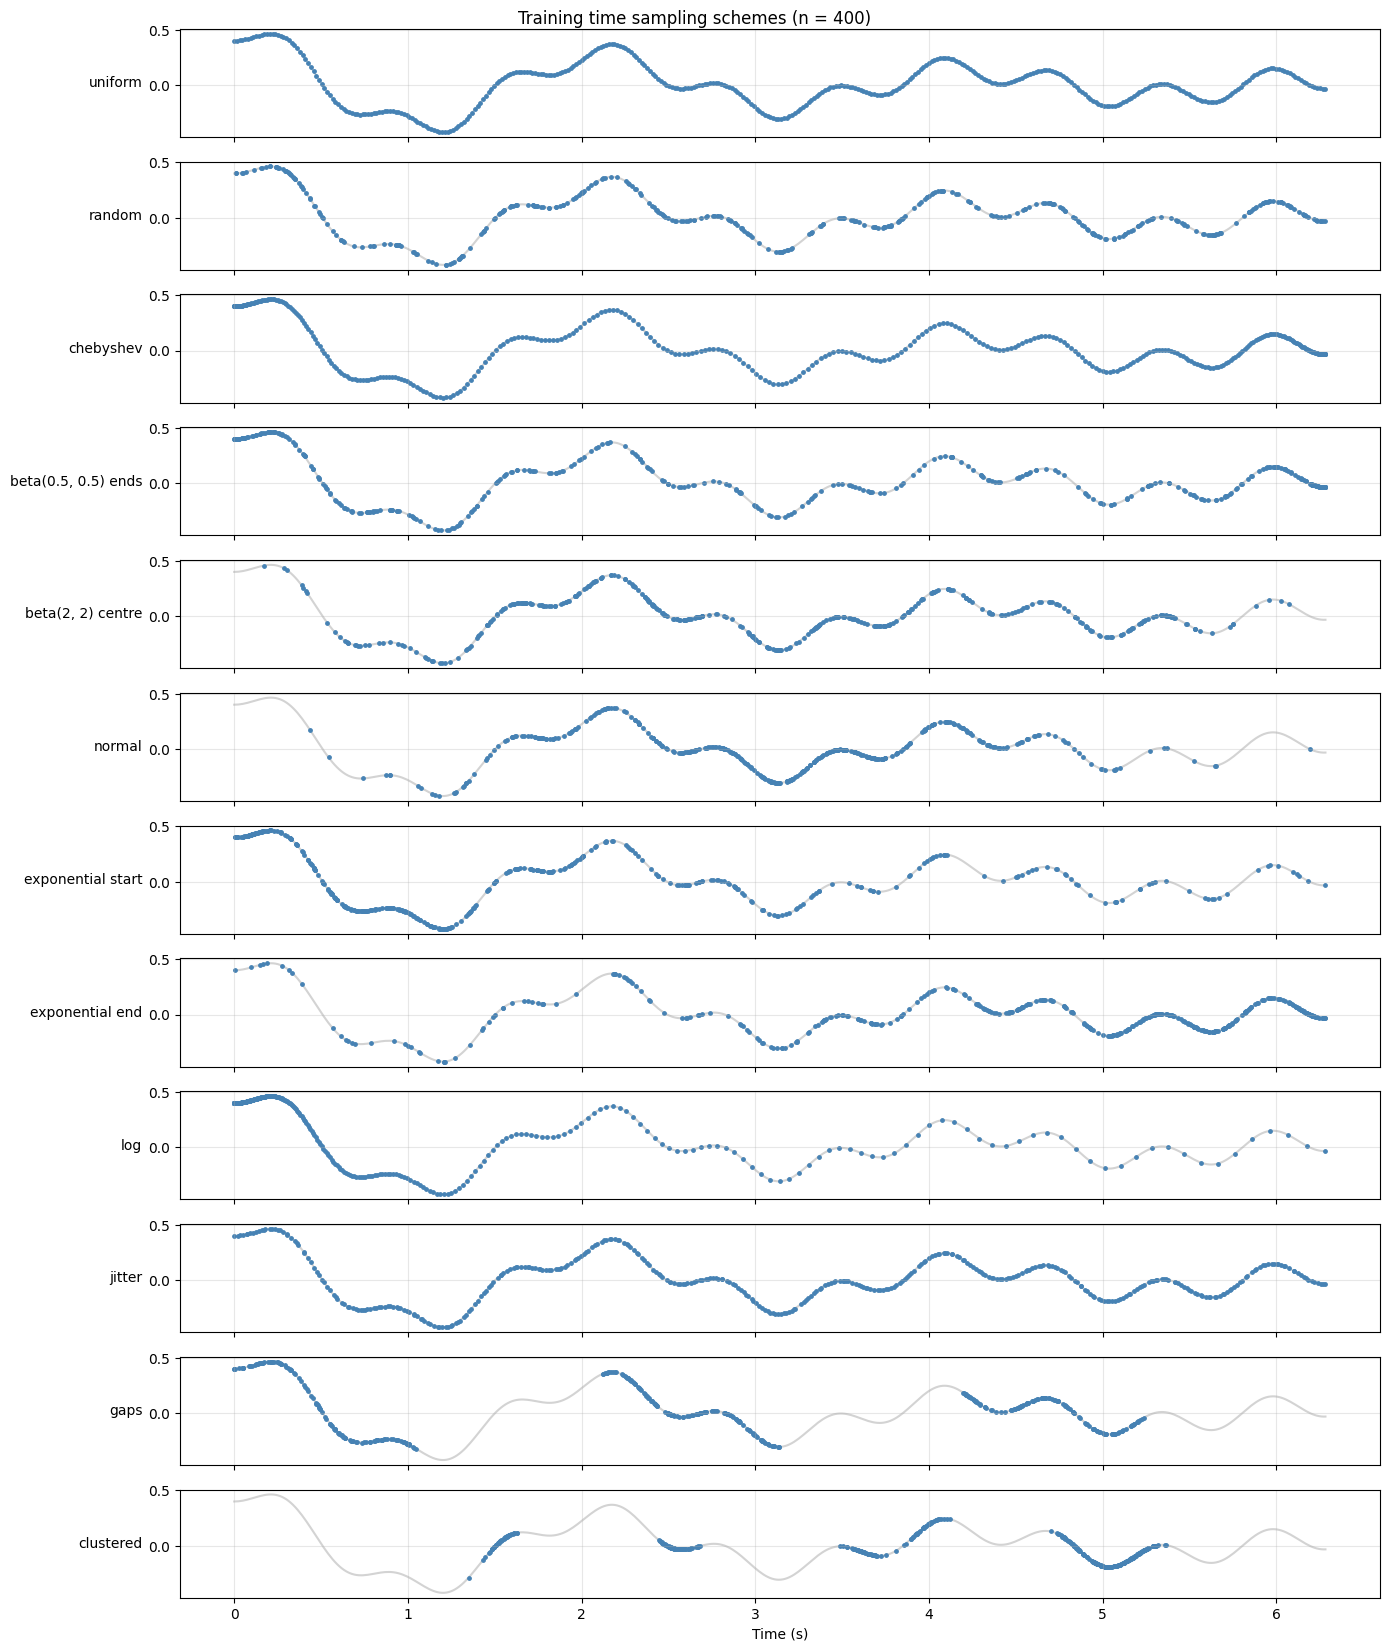

In [5]:
schemes = {
    "uniform":             ("uniform", {}),
    "random":              ("random", {}),
    "chebyshev":           ("chebyshev", {}),
    "beta(0.5, 0.5) ends": ("beta", {"a": 0.5, "b": 0.5}),
    "beta(2, 2) centre":   ("beta", {"a": 2, "b": 2}),
    "normal":              ("normal", {}),
    "exponential start":   ("exponential", {}),
    "exponential end":     ("exponential", {"reverse": True}),
    "log":                 ("log", {}),
    "jitter":              ("jitter", {"jitter": 0.3}),
    "gaps":                ("gaps", {"n_windows": 3, "duty": 0.5}),
    "clustered":           ("clustered", {"n_clusters": 8}),
    # "custom":            ("custom", {"density": lambda t: 1 + np.sin(base_cfg.omega * t)**2}),
}

plot_sampling_schemes(schemes, 0.0, base_cfg.n_periods_train * base_cfg.T, base_cfg.n_points,
                      seed=base_cfg.seed_train,
                      x_fn=lambda t: base_cfg.oscillator.solution(t, *base_cfg.initial_conditions))

## 3. Single experiment: ANN vs PINN in detail

Pick one training sampling scheme and inspect everything.

In [6]:
#cfg = base_cfg.with_sampling("uniform")
cfg = base_cfg.with_sampling("clustered", n_clusters=5)

#### Data

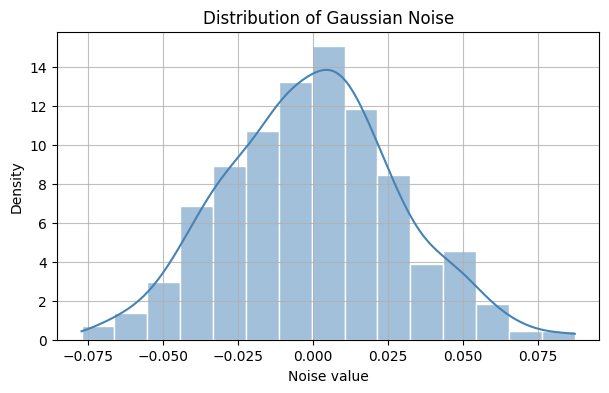

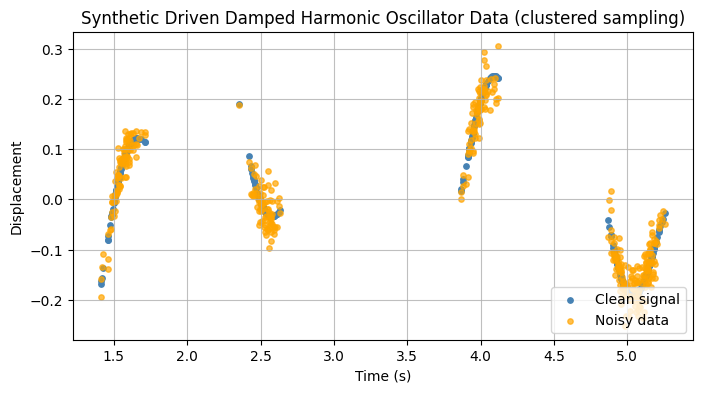

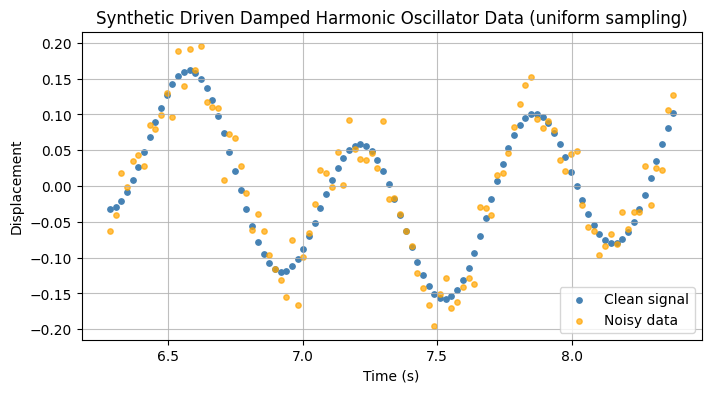

In [7]:
data = generate_data(cfg, plot=True)

#### Training both models

**Model 1: plain ANN (data only).** The network only sees the noisy observations. It minimizes

$$\mathcal{L}_{ANN} = \frac{1}{N}\sum_{i=1}^{N}\left(\hat{x}(t_i) - x_i^{noisy}\right)^2$$

Nothing tells it that the signal is an oscillator, so outside the training window it has no information to rely on.

**Model 2: PINN.** Same architecture, same data, same initial weights. The loss now also includes physics:

$$\mathcal{L}_{PINN} = \underbrace{\frac{1}{N}\sum_{i=1}^{N}\left(\hat{x}(t_i) - x_i^{noisy}\right)^2}_{\mathcal{L}_{data}}
+ \lambda_{phys}\underbrace{\frac{1}{M}\sum_{j=1}^{M}r(t_j)^2}_{\mathcal{L}_{phys}}
+ \lambda_{IC}\underbrace{\left[(\hat{x}(0)-x_0)^2 + (\dot{\hat{x}}(0)-v_0)^2\right]}_{\mathcal{L}_{IC}}$$

with the ODE residual
$$r(t) = \ddot{\hat{x}} + 2\zeta\omega\dot{\hat{x}} + \omega^2\hat{x} - F_0\cos(\Omega t)$$

- $\mathcal{L}_{phys}$ is evaluated on **collocation points** $t_j$. These don't need measurements, so they can extend beyond the data window (`colloc_t_end`, or `colloc_test_window=True` to cover the whole test window).
- $\mathcal{L}_{IC}$ uses the known initial state of the oscillator.

In [8]:
res = run_experiment(cfg, verbose=True)
print(res.model_ann)

[clustered] Training ANN ...
Epoch 2000/10000, Loss: 0.048688
Epoch 4000/10000, Loss: 0.046681
Epoch 6000/10000, Loss: 0.046232
Epoch 8000/10000, Loss: 0.045336
Epoch 10000/10000, Loss: 0.044454
[clustered] Training PINN ...
Epoch 2000/20000 | Total: 11.74357 | Data: 0.27410 | Physics: 11.37169 | IC: 0.09778
Epoch 4000/20000 | Total: 6.42311 | Data: 0.09202 | Physics: 6.25810 | IC: 0.07299
Epoch 6000/20000 | Total: 4.16805 | Data: 0.18117 | Physics: 3.72795 | IC: 0.25893
Epoch 8000/20000 | Total: 0.31689 | Data: 0.06066 | Physics: 0.17213 | IC: 0.08410
Epoch 10000/20000 | Total: 0.29695 | Data: 0.06090 | Physics: 0.15824 | IC: 0.07782
Epoch 12000/20000 | Total: 0.28850 | Data: 0.05967 | Physics: 0.15175 | IC: 0.07708
Epoch 14000/20000 | Total: 0.07852 | Data: 0.04937 | Physics: 0.02256 | IC: 0.00659
Epoch 16000/20000 | Total: 0.04882 | Data: 0.04776 | Physics: 0.00106 | IC: 0.00000
Epoch 18000/20000 | Total: 0.04841 | Data: 0.04778 | Physics: 0.00062 | IC: 0.00001
Epoch 20000/20000 | T

### 3.1 Model 1 — Plain ANN

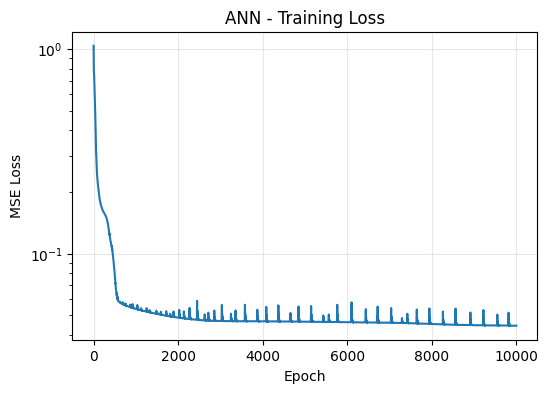

In [9]:
plot_ann_loss(res)

#### Training set fit

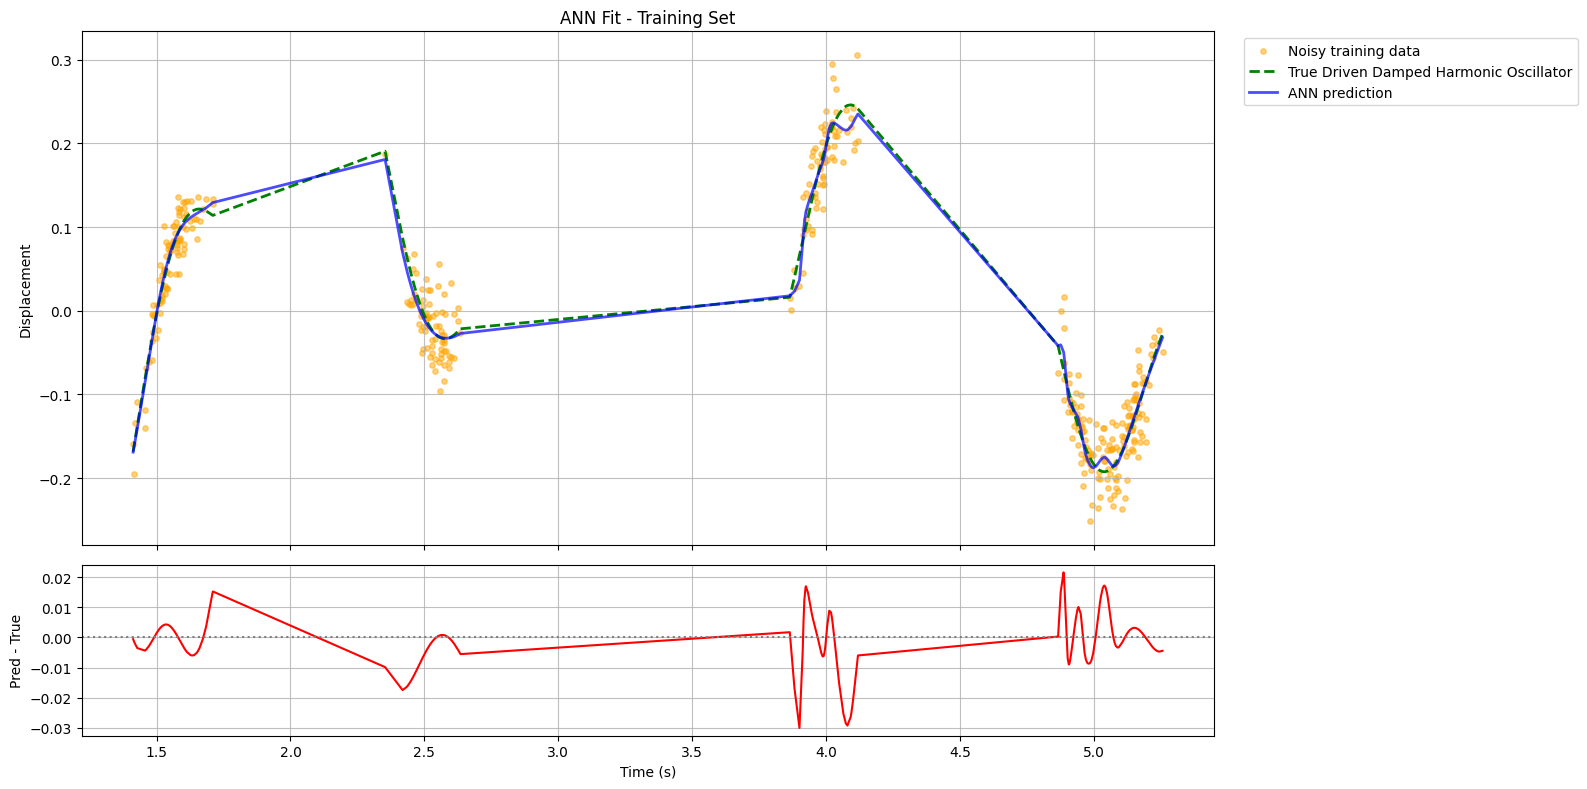

In [10]:
plot_model_fit(res, "ann", "train")

#### Test set (forecasting)

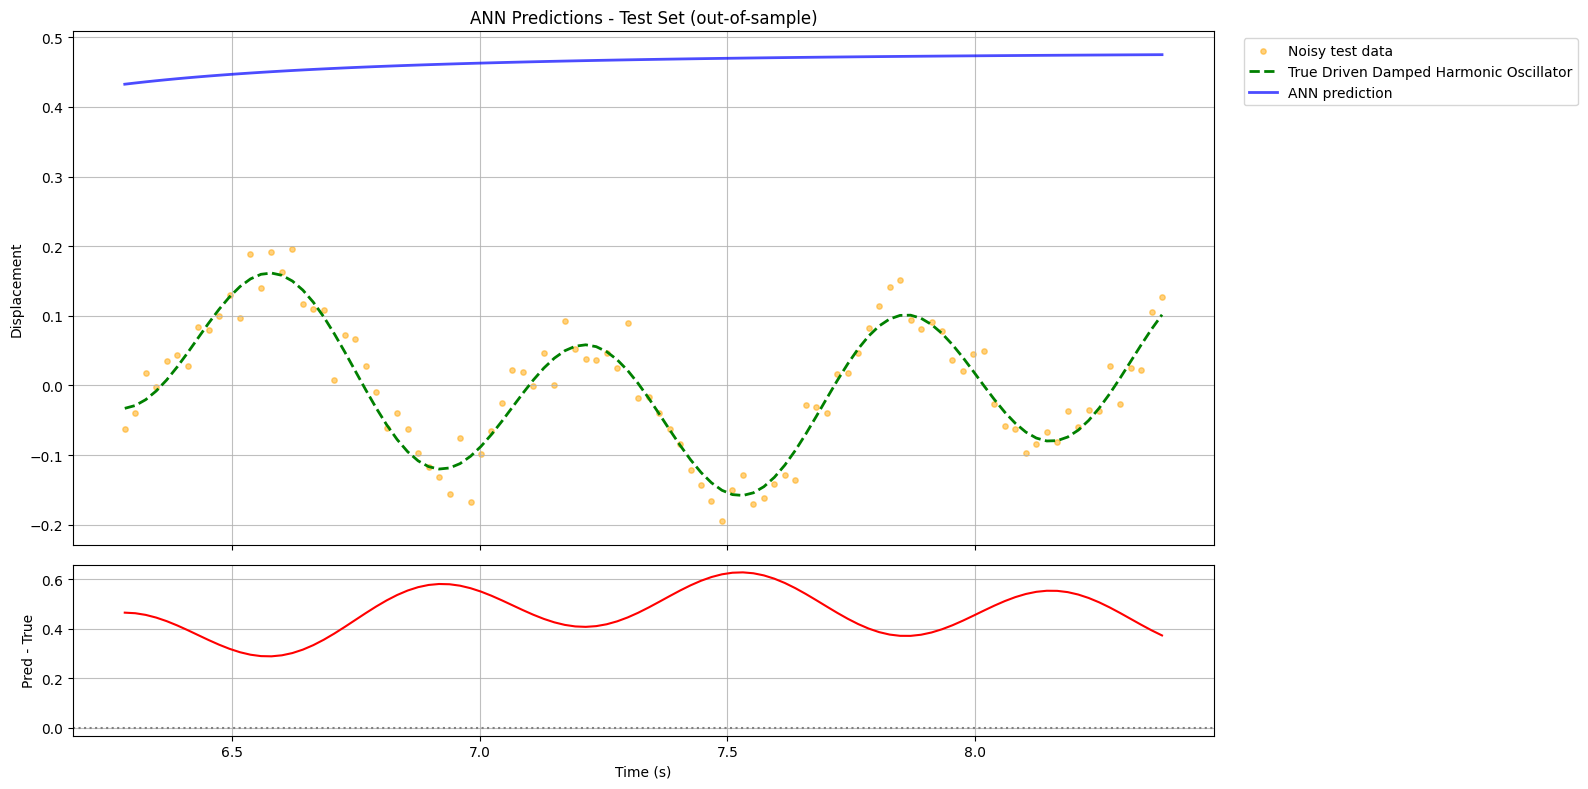

In [11]:
plot_model_fit(res, "ann", "test")

### 3.2 Model 2 — PINN

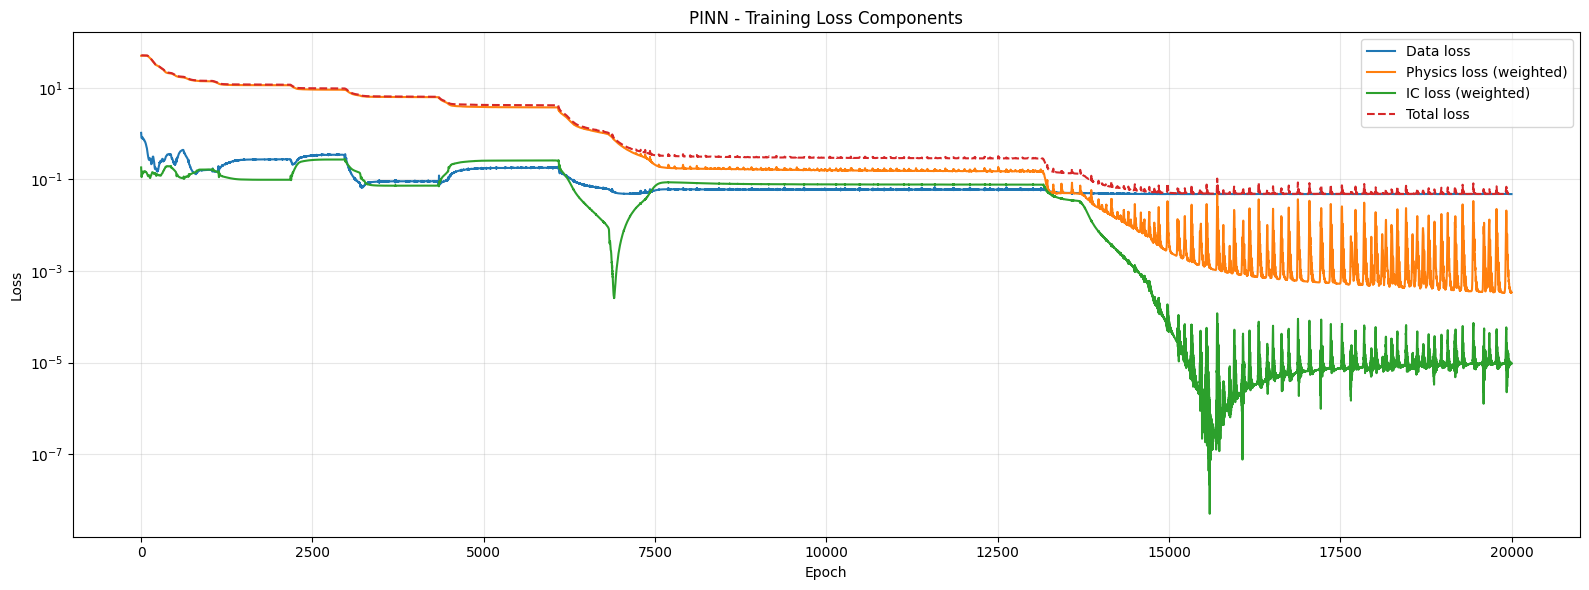

In [12]:
plot_pinn_losses(res)

#### Training set fit

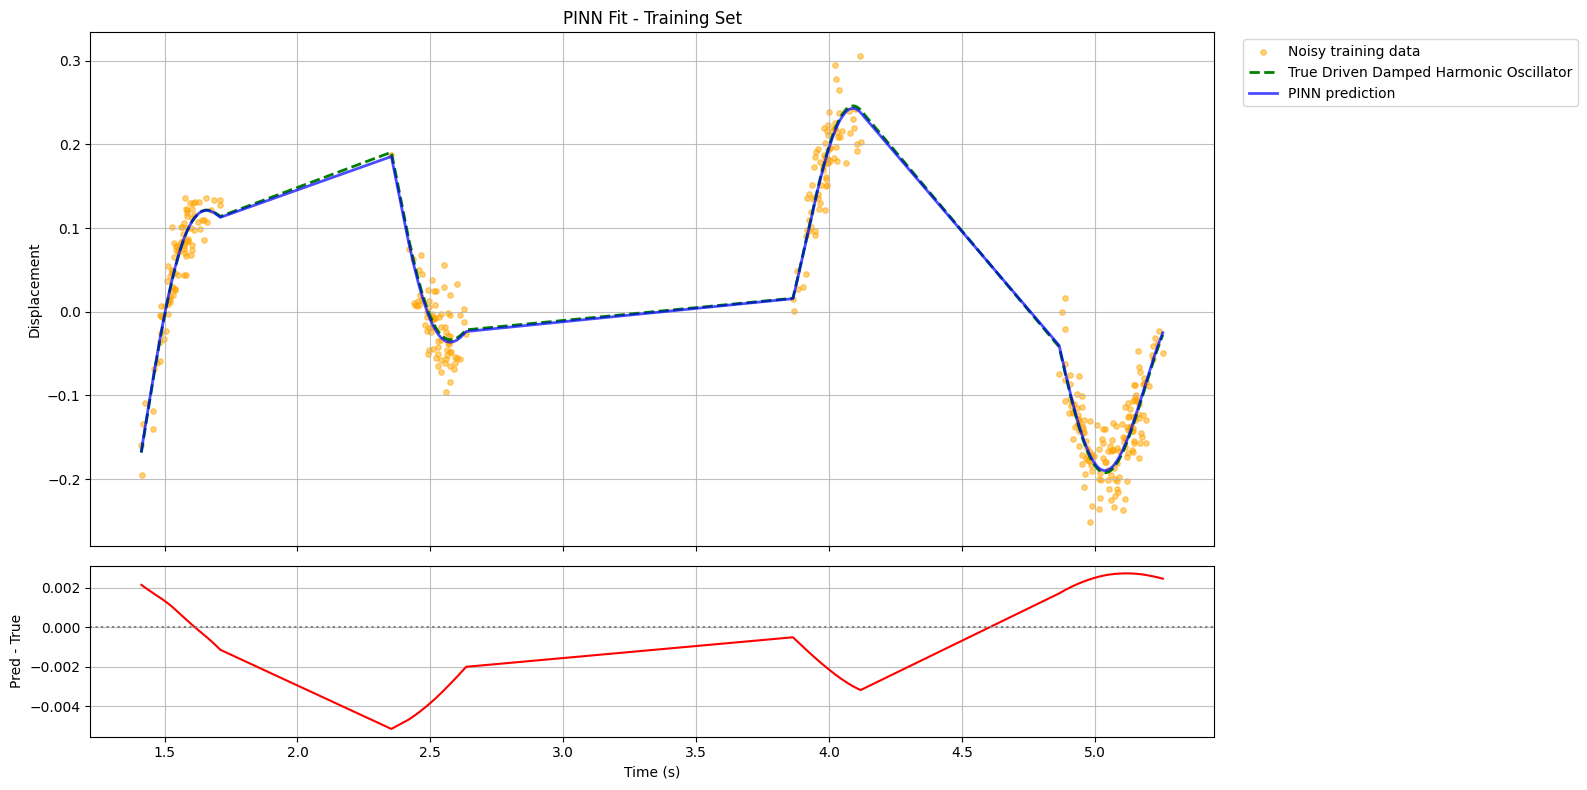

In [13]:
plot_model_fit(res, "pinn", "train")

#### Test set (forecasting)

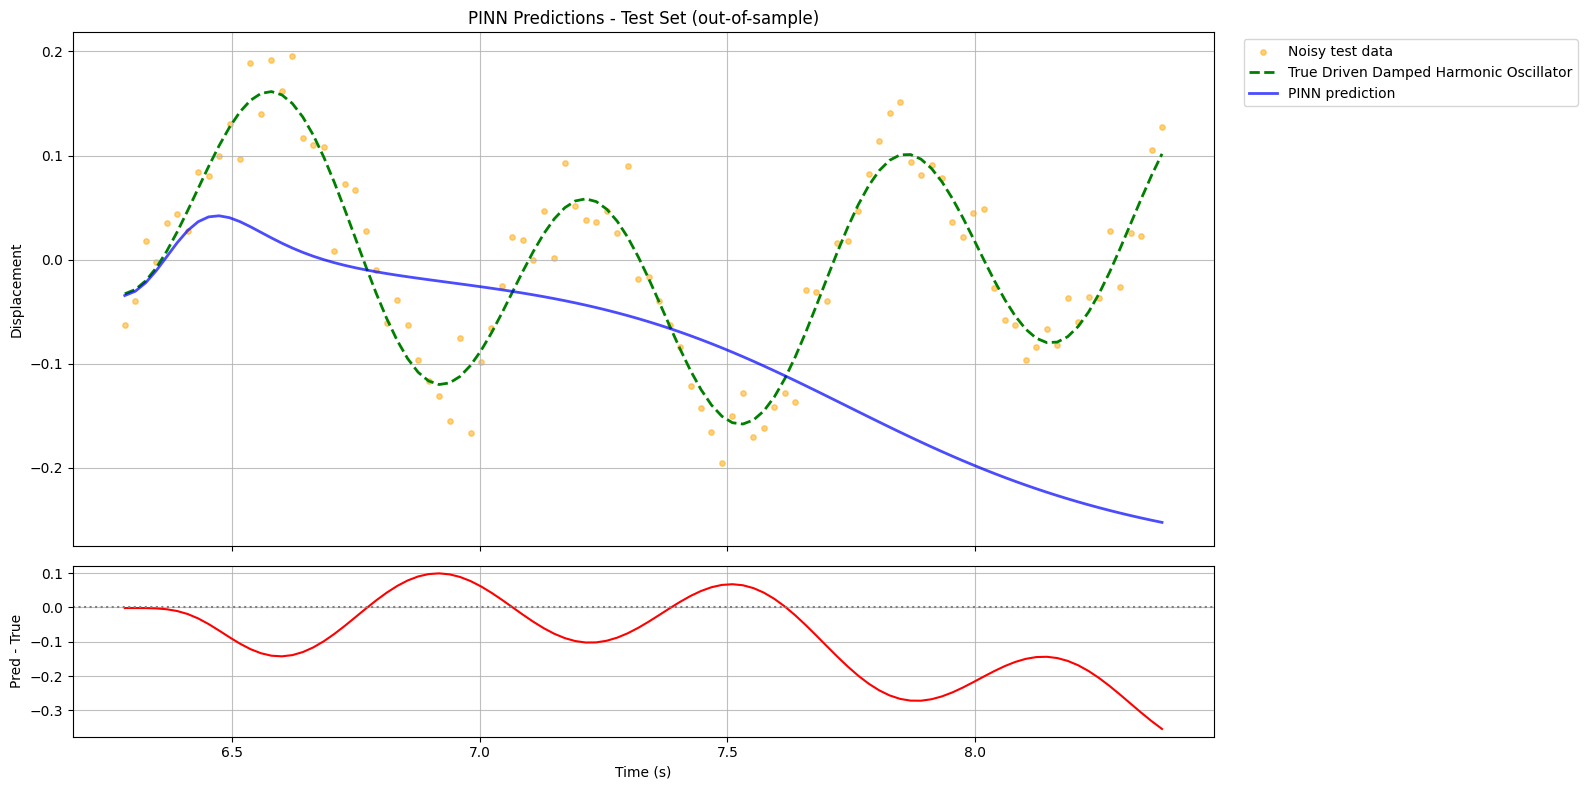

In [14]:
plot_model_fit(res, "pinn", "test")

### 3.3 ANN vs PINN — head-to-head

Several views of the same question: *did the model learn the oscillator, or just the data?*
1. **Data loss vs noise floor:** how closely each model chases the noisy points.
2. **Predictions over training + test windows.**
3. **Prediction error over time**, against the true signal.
4. **Physical consistency:** how well each model satisfies the ODE.
5. **Phase portrait** $(x, \dot{x})$.
6. **Power spectrum:** which frequencies each model reproduces.
7. **Metrics table.**

#### 1. Data loss vs noise floor
With independent Gaussian noise, a model that recovers the *true* signal cannot push the data MSE below the noise variance (in normalized units: $(\sigma_{noise}/\sigma_x)^2$). A data loss **below** this floor means the model is fitting the noise.

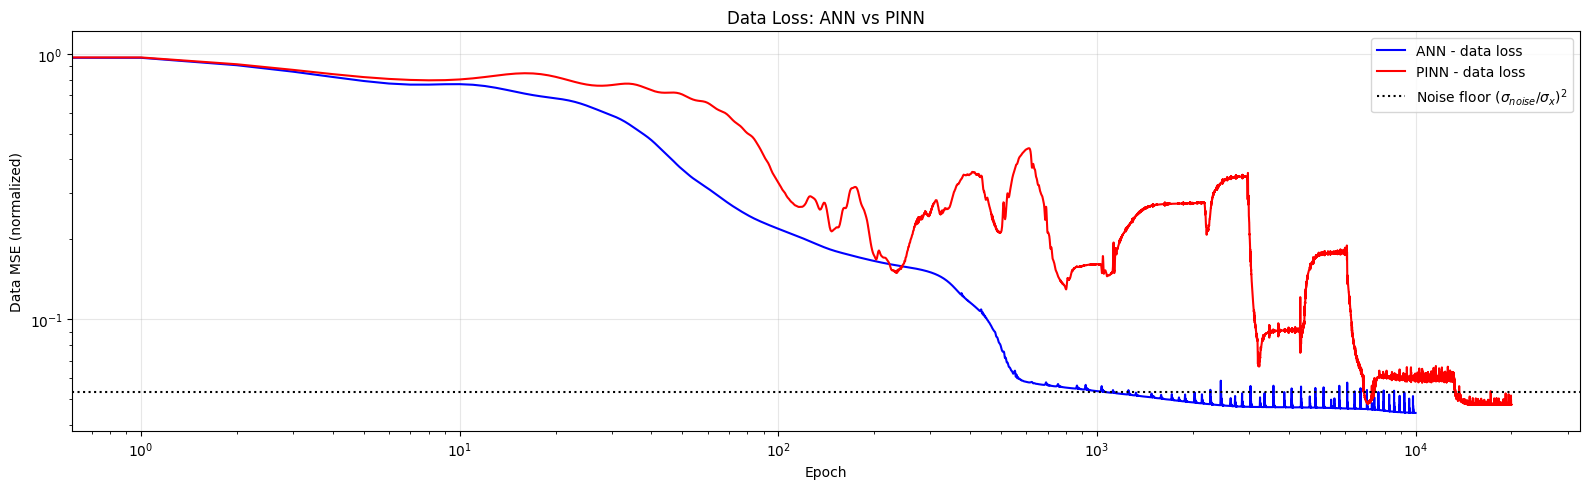

In [15]:
plot_data_loss_vs_noise_floor(res)

#### 2. Predictions over training + test windows

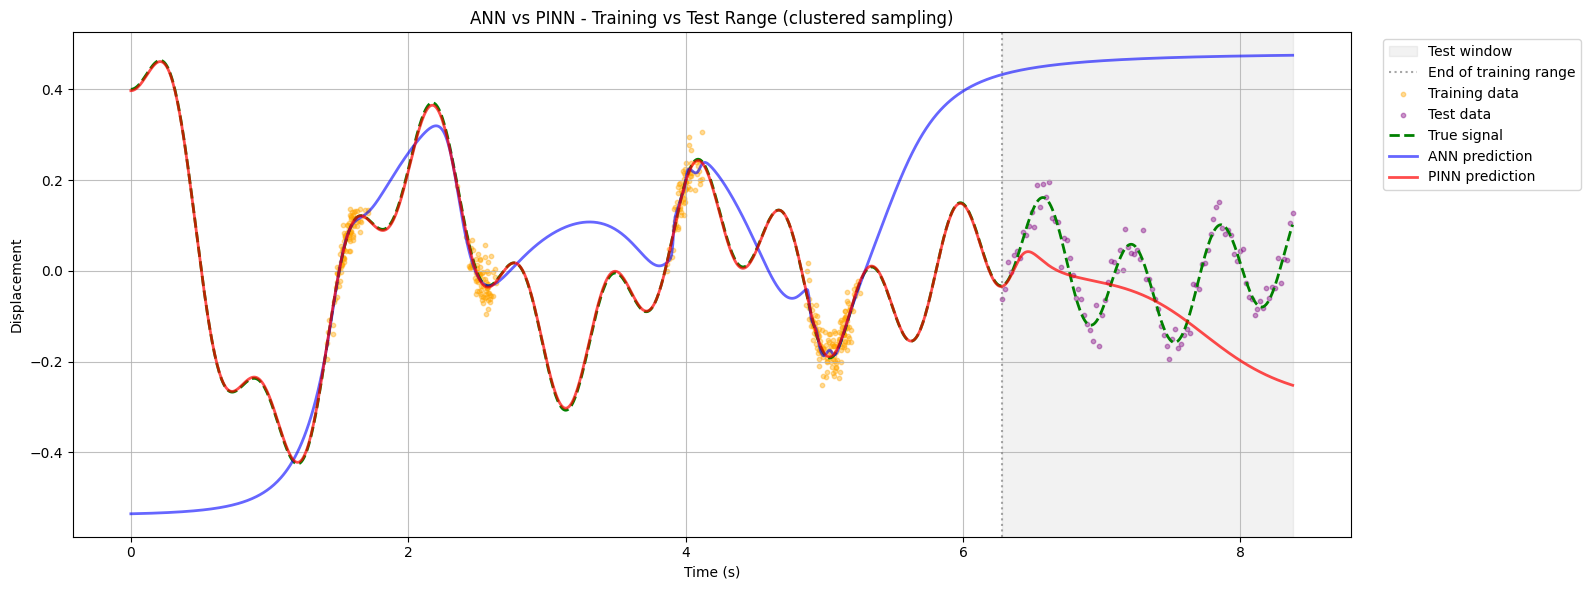

In [16]:
plot_predictions_full(res)

#### 3. Prediction error over time (vs true signal)

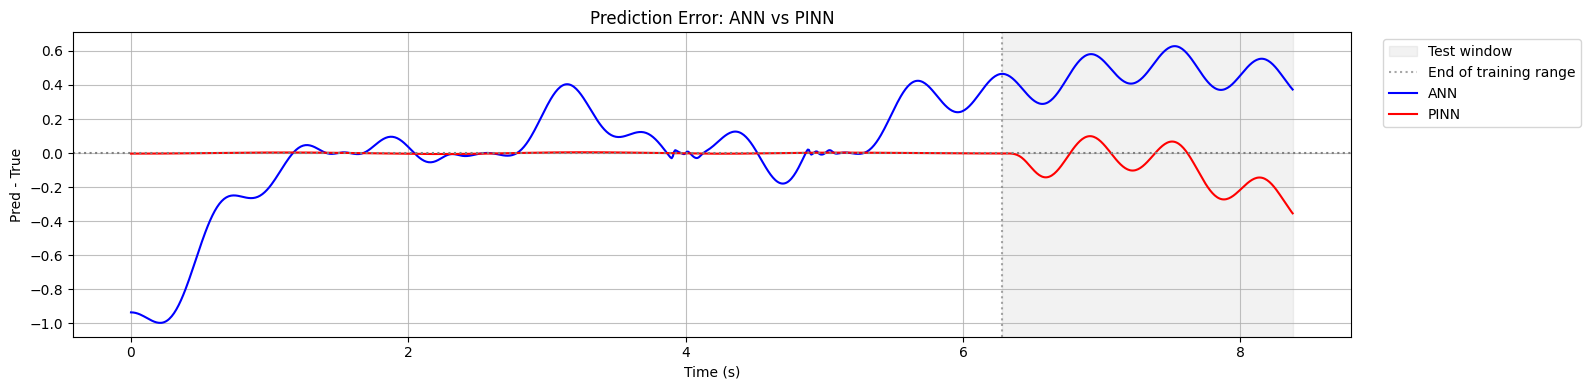

In [17]:
plot_error_full(res)

#### 4. Physical consistency
Evaluate the ODE residual $r(t) = \ddot{\hat{x}} + 2\zeta\omega\dot{\hat{x}} + \omega^2\hat{x} - F_0\cos(\Omega t)$ of **both** trained models over the full time range. The true solution has $r(t) = 0$ everywhere. The ANN was never asked to satisfy this, so it measures how "physical" a purely data-driven fit is.

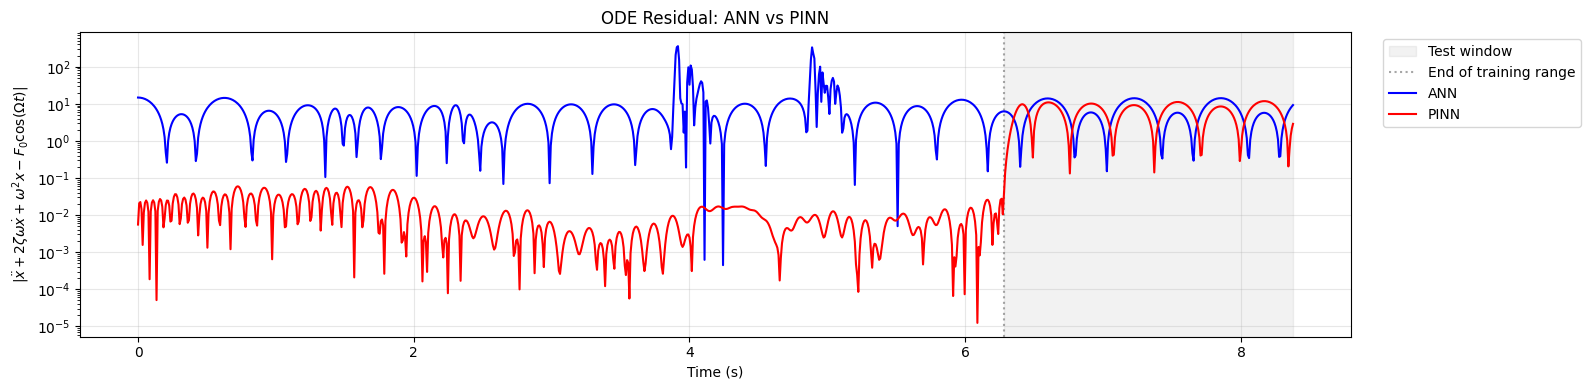

In [18]:
plot_ode_residual(res)

#### 5. Phase portrait
Velocities $\dot{\hat{x}}(t)$ of the networks come from autograd; the true one is analytic. The true trajectory spirals in from the initial condition and settles on the steady-state ellipse of the driving force (an attracting periodic orbit). A model that only fits the data has no reason to reach it.

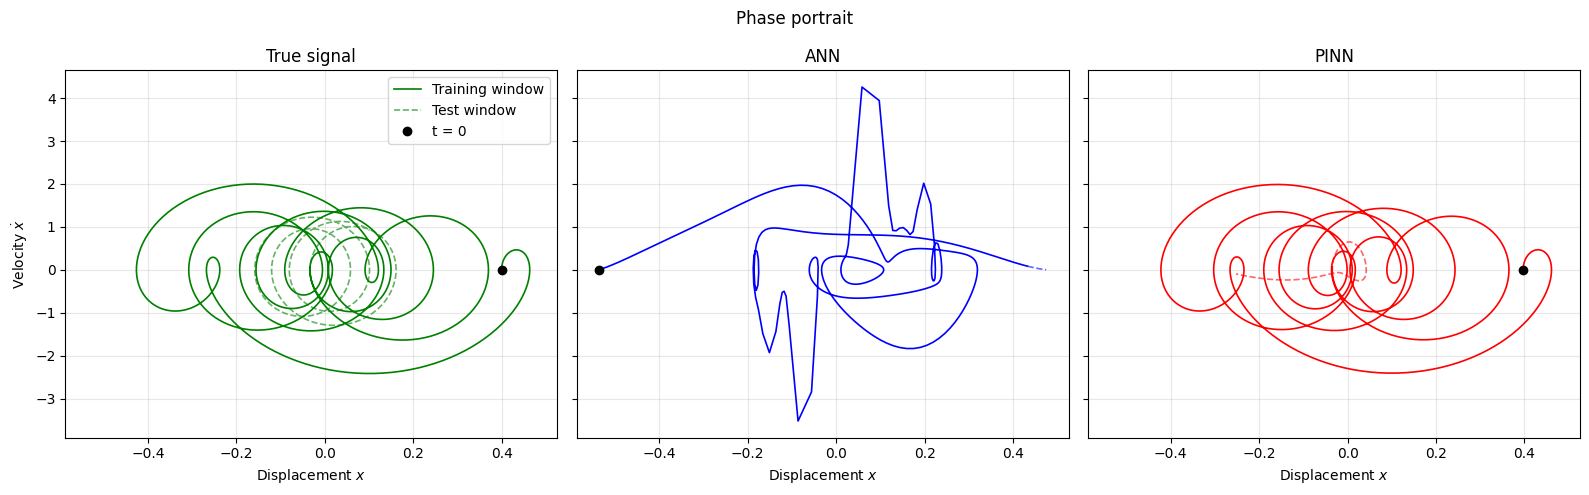

In [19]:
plot_phase_portrait(res)

#### 6. Power spectrum
$|\mathrm{FFT}(x)|^2$ over the training + test windows (normalized to its peak). The true signal has two peaks: the transient at $\omega_d$ and the steady state at $\Omega$. The windows are short, so the peaks are broad.

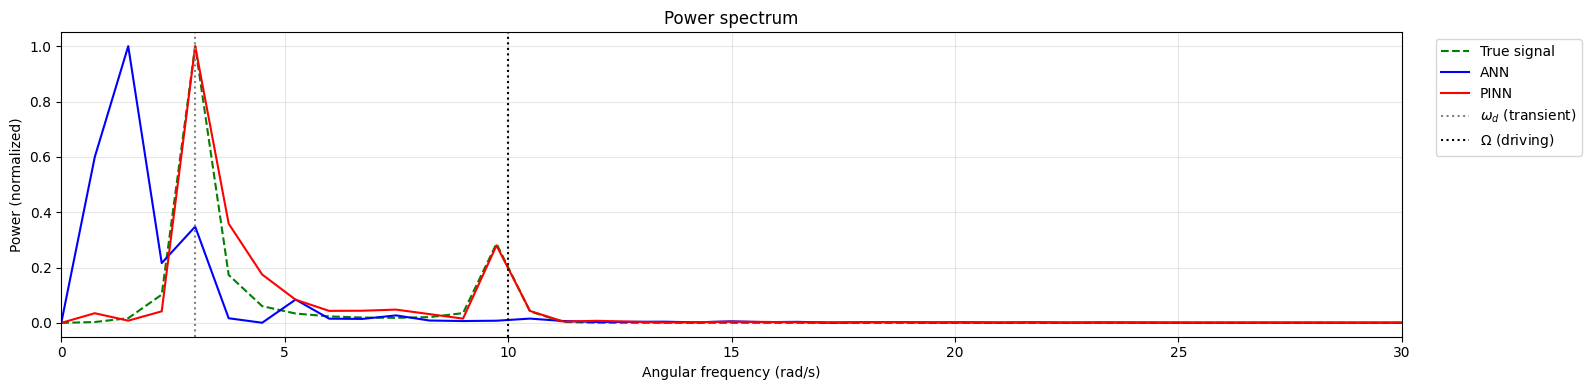

In [20]:
plot_power_spectrum(res)

#### 7. Metrics

In [21]:
display(res.metrics.round(4))
display(res.physics_rms.to_frame().round(4))

ANN                             PINN                  \
                     MSE    RMSE     MAE       R2     MSE    RMSE     MAE   
Train (vs noisy)  0.0008  0.0274  0.0218   0.9554  0.0008  0.0284  0.0224   
Train (vs true)   0.0001  0.0076  0.0054   0.9965  0.0000  0.0024  0.0022   
Test (vs noisy)   0.2244  0.4737  0.4639 -25.2614  0.0218  0.1475  0.1174   
Test (vs true)    0.2254  0.4747  0.4663 -29.9085  0.0202  0.1420  0.1122   

                          
                      R2  
Train (vs noisy)  0.9521  
Train (vs true)   0.9996  
Test (vs noisy)  -1.5473  
Test (vs true)   -1.7648

,ODE residual RMS
ANN,25.483101
PINN,3.607100


### 3.4 Enforcing the physics over the forecast window

The PINN above only evaluates the ODE on the training window, so in the test window it extrapolates just like the ANN (only better initialized by the physics). Collocation points need **no measurements**, so we can also place them over the test window: the PINN is then *solving the ODE forward*, anchored by the data and the initial conditions. The ANN has no equivalent. Same data, same weights, only `colloc_test_window=True`.

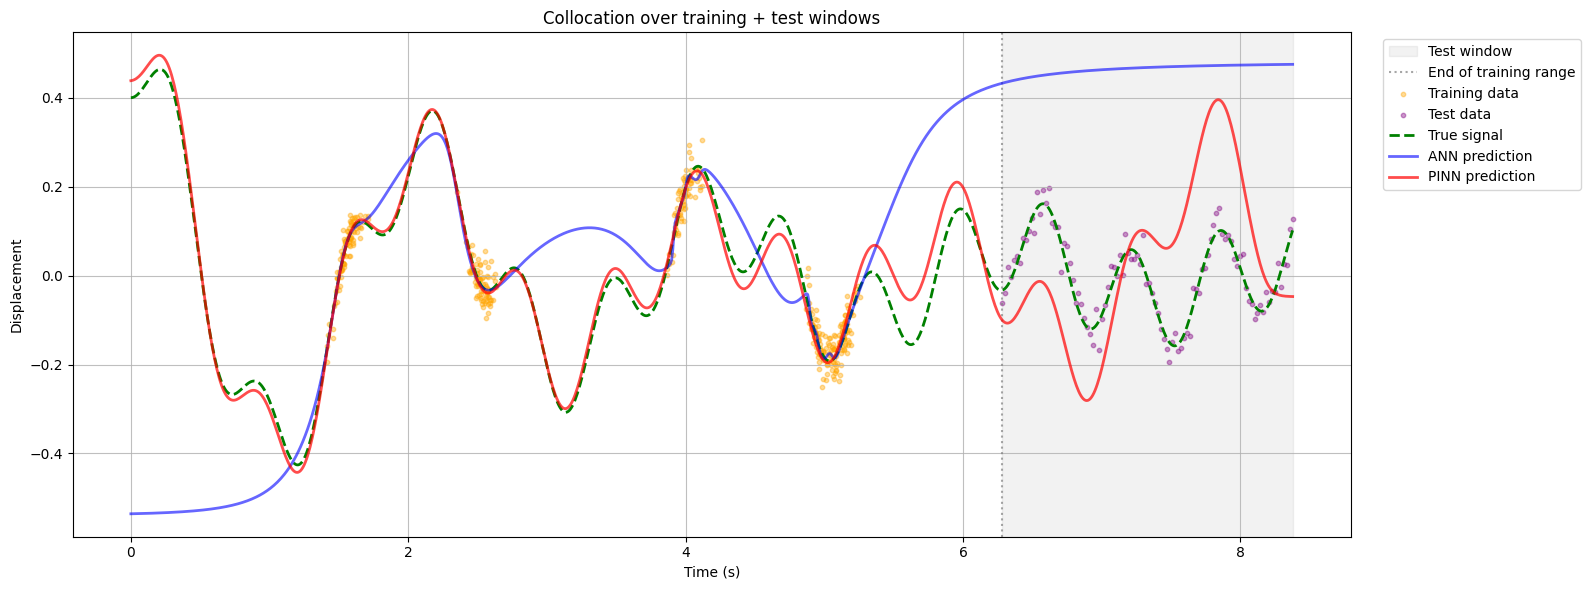

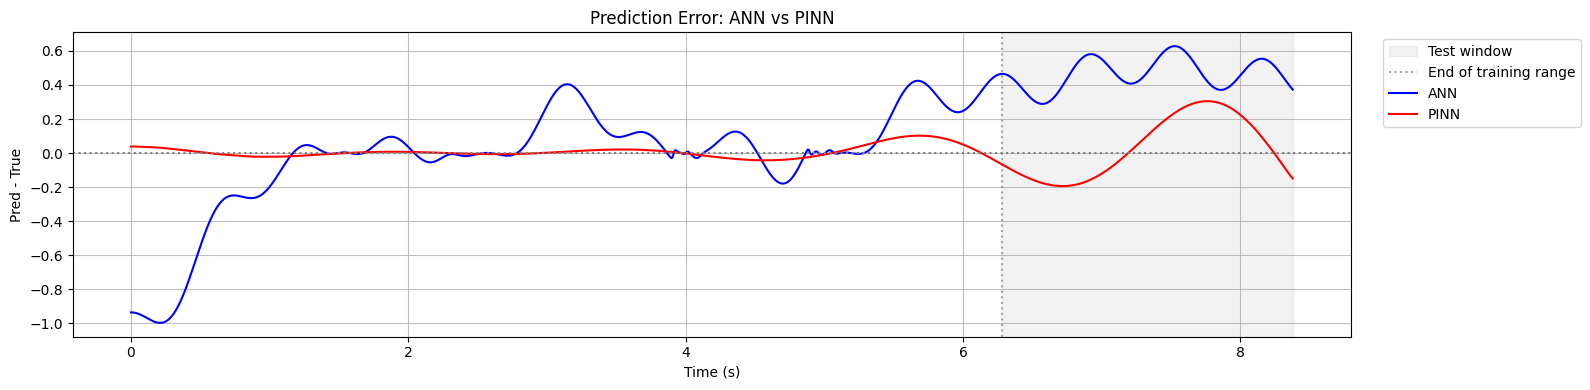

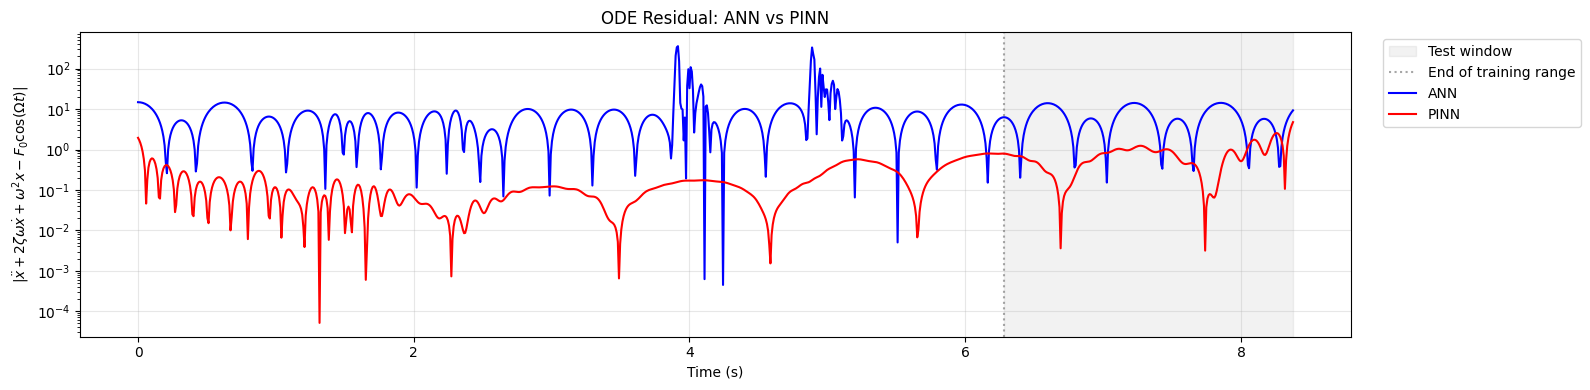

,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS
,ANN,ANN,ANN,ANN,PINN,PINN,PINN,PINN
collocation: training window,0.0076,0.4747,-29.9085,25.483101,0.0024,0.142,-1.7648,3.6071
collocation: training + test window,0.0076,0.4747,-29.9085,25.483101,0.0109,0.181,-3.4937,0.5565


In [22]:
cfg_ext = replace(cfg, colloc_test_window=True)
res_ext = run_experiment(cfg_ext, verbose=False)

plot_predictions_full(res_ext, title="Collocation over training + test windows")
plot_error_full(res_ext)
plot_ode_residual(res_ext)
display(summarize({"collocation: training window": res,
                   "collocation: training + test window": res_ext}).round(4))

## 4. Sampling-scheme sweep

Same oscillator, same noise, same test set, same initial weights: only the **training time sampling** changes. Each scheme trains one ANN and one PINN, so the cost is `len(schemes)` × (ANN + PINN) trainings (about 6-8 min per scheme on CPU). Lower `pinn_epochs` in `sweep_cfg` for a quick first look, and set `colloc_test_window=True` to sweep the setting of Section 3.4 instead.

In [23]:
sweep_cfg = replace(base_cfg, pinn_epochs=20_000)
sweep_schemes = schemes  # or a subset, e.g. {k: schemes[k] for k in ["uniform", "gaps", "clustered"]}

results, summary = compare_sampling_schemes(sweep_cfg, sweep_schemes)

Running uniform ...
Running random ...
Running chebyshev ...
Running beta(0.5, 0.5) ends ...
Running beta(2, 2) centre ...
Running normal ...
Running exponential start ...
Running exponential end ...
Running log ...
Running jitter ...
Running gaps ...
Running clustered ...


#### Summary (all metrics against the true signal)

In [24]:
display(summary.round(4))

,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS
,ANN,ANN,ANN,ANN,PINN,PINN,PINN,PINN
uniform,0.0117,0.3433,-15.1613,8.582700,0.0058,0.4442,-26.0643,3.6428
random,0.0127,0.2435,-7.1312,39.796700,0.0105,0.9656,-126.8552,5.1975
chebyshev,0.0123,0.1354,-1.5140,12.498700,0.0046,0.6242,-52.4324,4.1363
"beta(0.5, 0.5) ends",0.0132,0.1381,-1.6154,15.965200,0.0017,0.2740,-9.2965,3.3403
"beta(2, 2) centre",0.0120,0.2065,-4.8473,51.814899,0.0021,0.1087,-0.6198,3.4054
normal,0.0101,0.1125,-0.7358,13.360800,0.0073,0.0901,-0.1143,3.4776
exponential start,0.0242,0.6184,-51.4401,11.017200,0.0011,0.4425,-25.8513,3.6454
exponential end,0.0109,0.0980,-0.3161,12.642800,0.0016,0.3519,-15.9867,3.5134
log,0.0248,0.1735,-3.1299,10.096900,0.0015,0.1576,-2.4043,3.3253


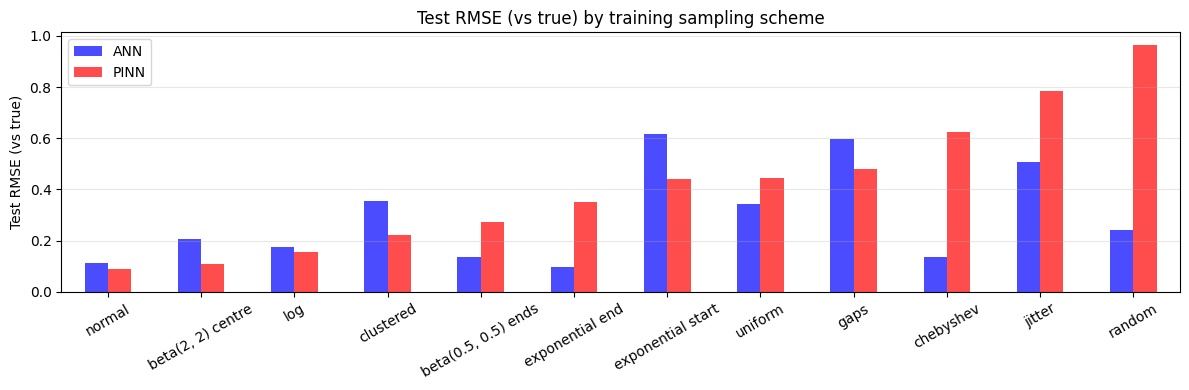

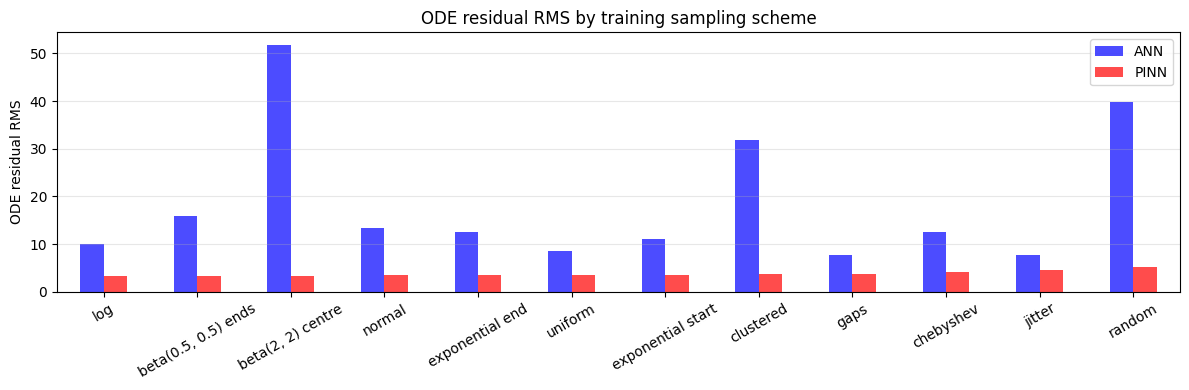

In [25]:
plot_summary_bars(summary, "Test RMSE (vs true)")
plot_summary_bars(summary, "ODE residual RMS")

#### Predictions per scheme

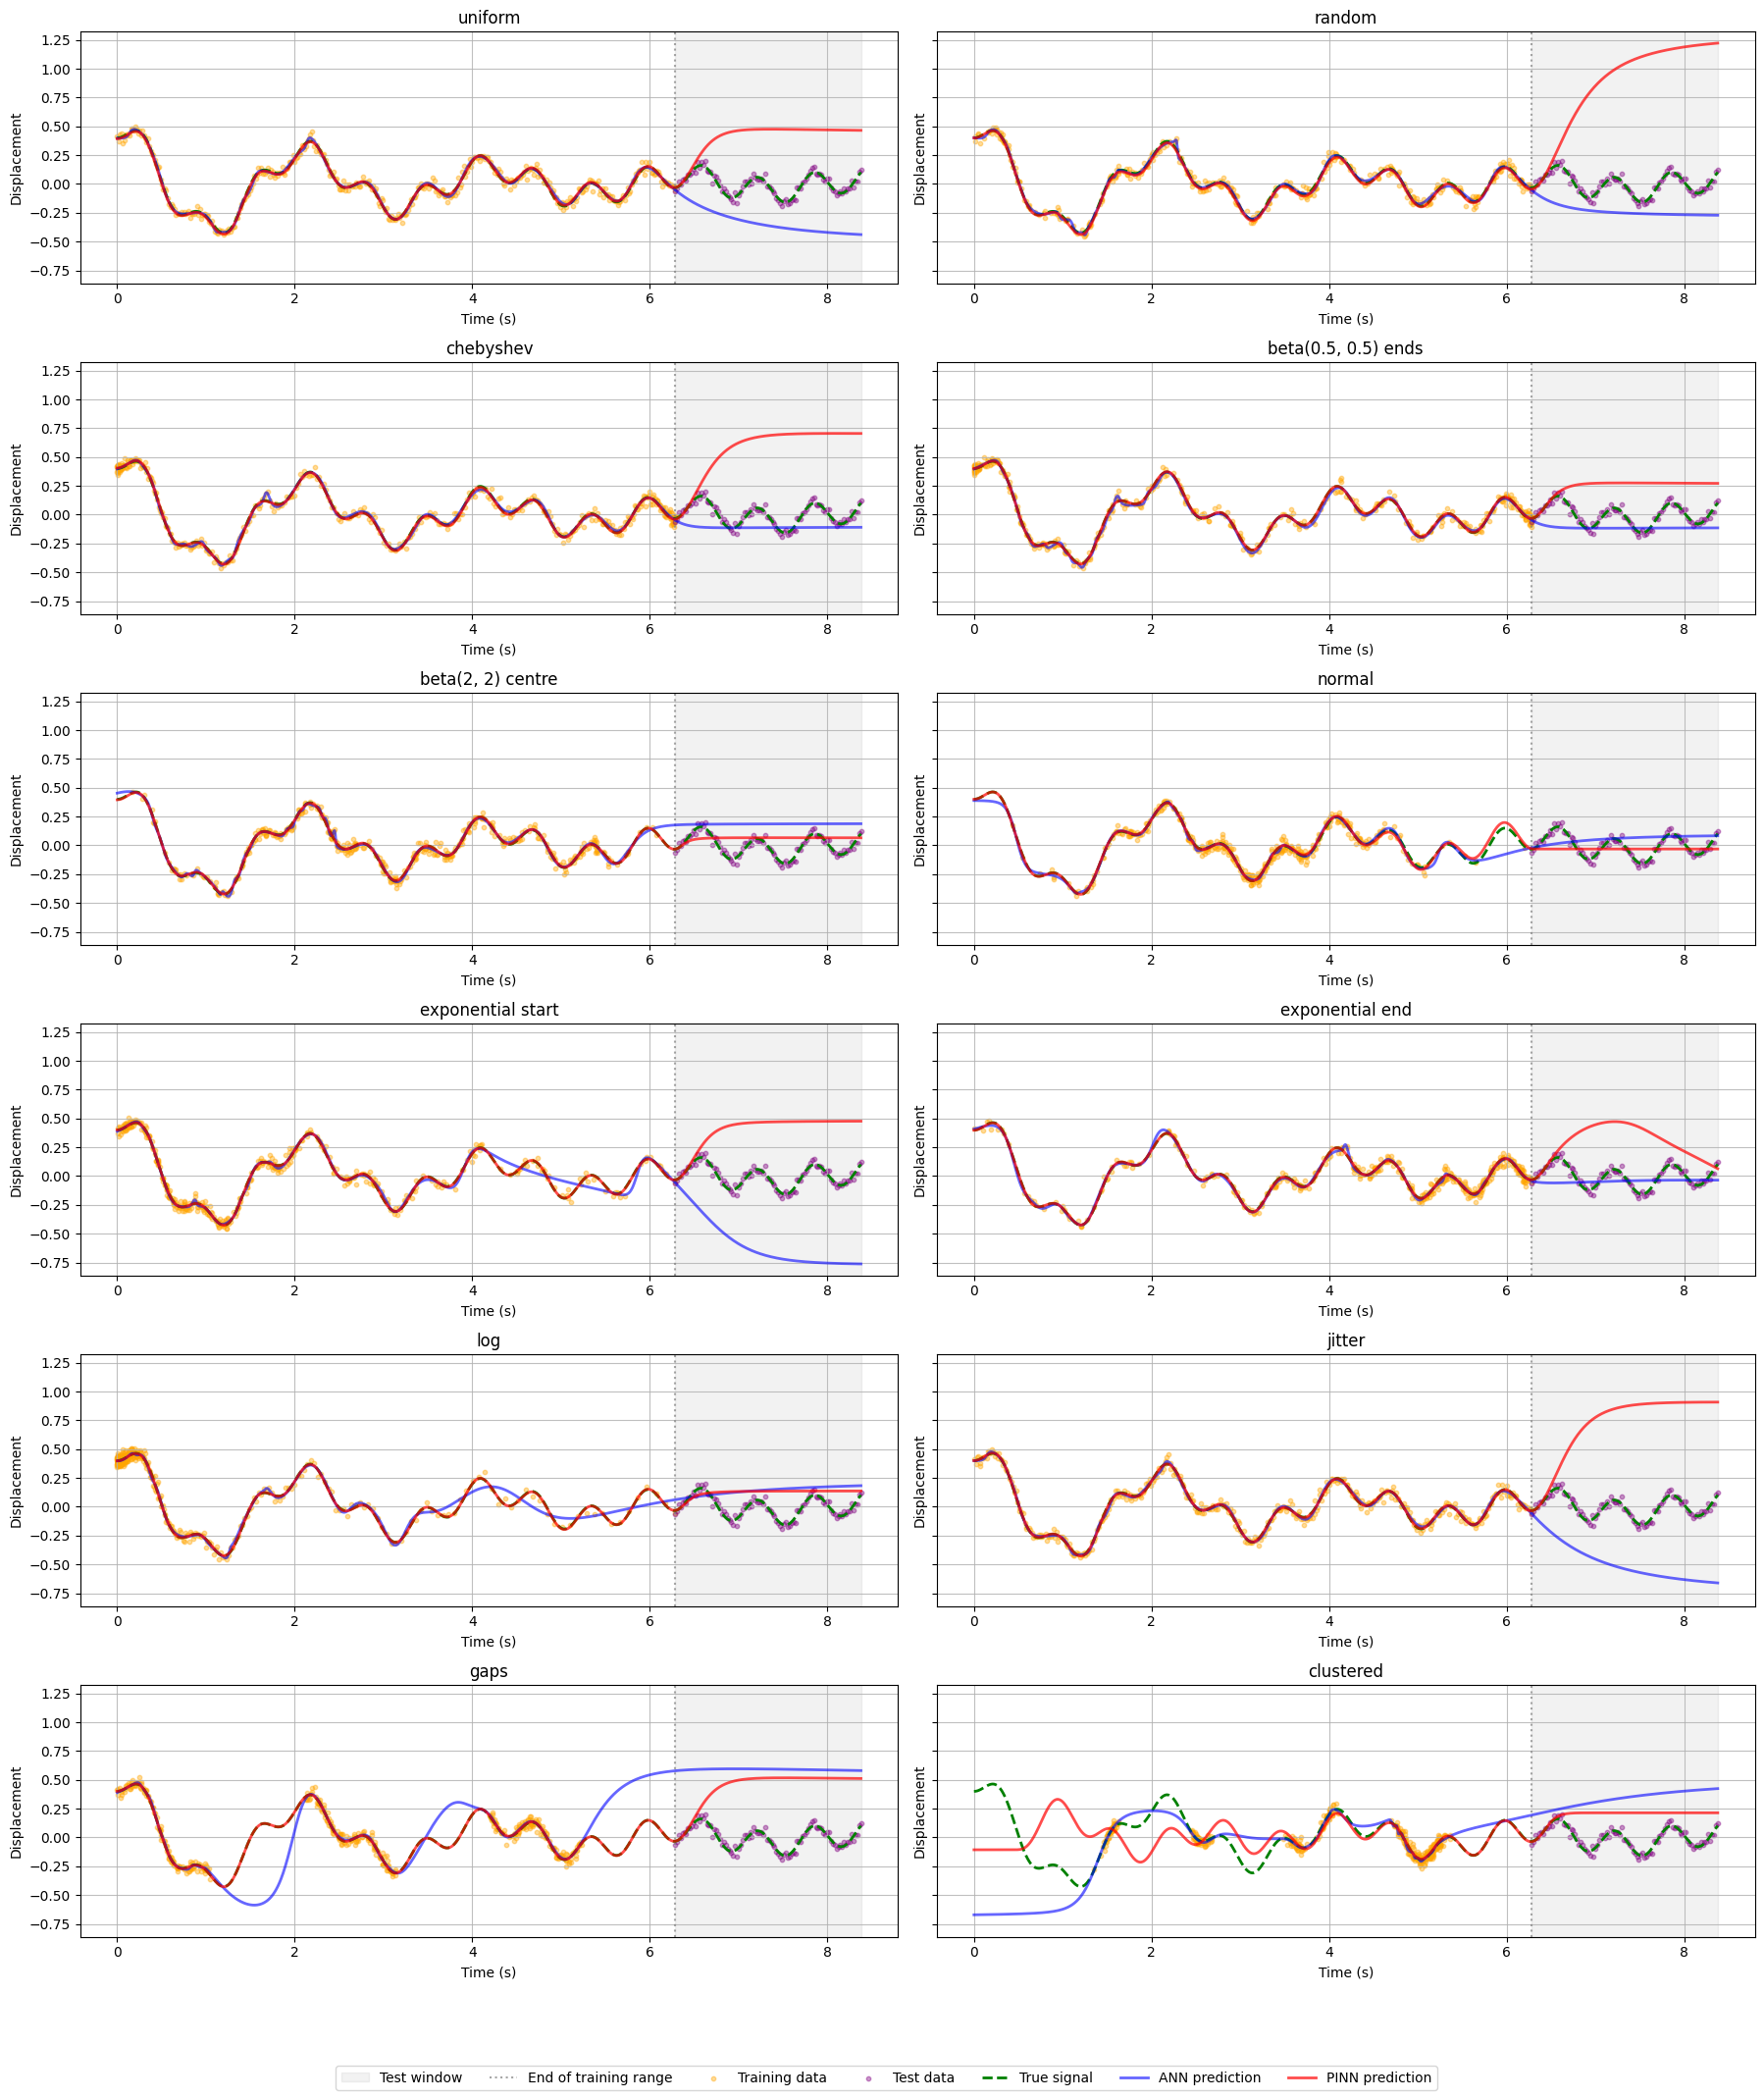

In [26]:
plot_predictions_grid(results, ncols=2)

#### Inspect one scheme in detail
Every entry of `results` is an `ExperimentResult`, so all the plots of Section 3 work on it.

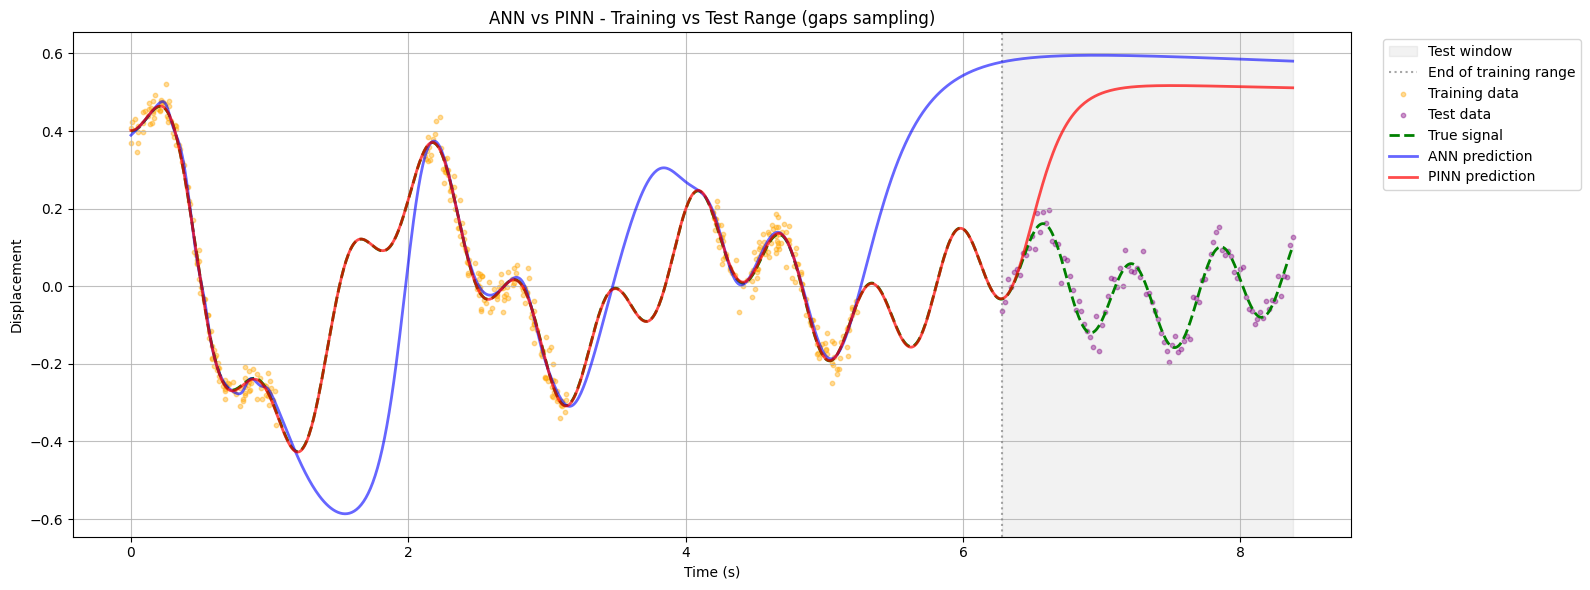

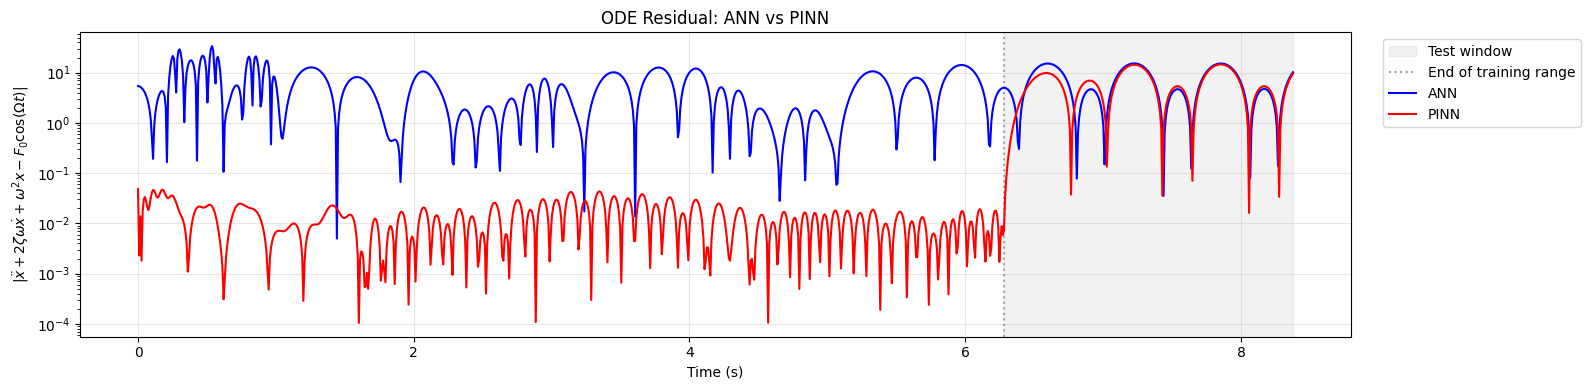

ANN                             PINN                  \
                     MSE    RMSE     MAE       R2     MSE    RMSE     MAE   
Train (vs noisy)  0.0008  0.0278  0.0221   0.9843  0.0008  0.0285  0.0226   
Train (vs true)   0.0001  0.0080  0.0066   0.9987  0.0000  0.0015  0.0013   
Test (vs noisy)   0.3562  0.5968  0.5895 -40.6863  0.2293  0.4788  0.4353   
Test (vs true)    0.3578  0.5982  0.5919 -48.0688  0.2300  0.4796  0.4360   

                           
                       R2  
Train (vs noisy)   0.9835  
Train (vs true)    1.0000  
Test (vs noisy)  -25.8331  
Test (vs true)   -30.5424

In [27]:
r = results["gaps"]
plot_predictions_full(r)
plot_ode_residual(r)
display(r.metrics.round(4))